In [1]:
import os
print(os.getcwd())

C:\Users\Adhira\Documents\portfolio\vehicle-signal-analytics\notebooks


In [5]:
import numpy as np
import pandas as pd

np.random.seed(42)
n = 5000

time = pd.date_range("2026-01-01 08:00:00", periods=n, freq="s")
t = np.arange(n)
speed = np.clip(60 + 30 * np.sin(2 * np.pi * t / 1500) + np.random.normal(0, 3, n), 0, 120)
rpm = 800 + speed * 25 + np.random.normal(0, 80, n)
coolant_temp = 70 + np.cumsum(np.random.normal(0.002, 0.05, n))

df = pd.DataFrame({
    "time": time,
    "speed": speed,
    "rpm": rpm,
    "coolant_temp": coolant_temp,
})

# Add 25 fake RPM spikes on purpose, so we can test our detection later
df["is_injected"] = 0
spike_rows = np.random.choice(n, 25, replace=False)
df.loc[spike_rows, "rpm"] += 2500
df.loc[spike_rows, "is_injected"] = 1

df.to_csv("../data/simulated_vehicle_signals.csv", index=False)
print(df.shape)
df.describe()

(5000, 5)


,time,speed,rpm,coolant_temp,is_injected
count,5000,5000.000000,5000.000000,5000.000000,5000.000000
mean,2026-01-01 08:41:39.500000,62.162796,2365.779996,74.413458,0.005000
min,2026-01-01 08:00:00,21.462703,1160.222089,69.332420,0.000000
25%,2026-01-01 08:20:49.750000,40.823433,1828.661341,70.803665,0.000000
50%,2026-01-01 08:41:39.500000,64.405830,2414.590066,73.359710,0.000000
75%,2026-01-01 09:02:29.250000,83.119444,2871.218117,77.927409,0.000000
max,2026-01-01 09:23:19,99.224002,5618.902634,82.686145,1.000000
std,NaN,21.528151,568.723389,3.906547,0.070541


In [3]:
print(df.isnull().sum())
df.describe()

time            0
speed           0
rpm             0
coolant_temp    0
is_injected     0
dtype: int64


,time,speed,rpm,coolant_temp,is_injected
count,5000,5000.000000,5000.000000,5000.000000,5000.000000
mean,2026-01-01 08:41:39.500000,91.706251,3104.366355,74.413458,0.005000
min,2026-01-01 08:00:00,23.333893,1301.210752,69.332420,0.000000
25%,2026-01-01 08:20:49.750000,67.092662,2480.987638,70.803665,0.000000
50%,2026-01-01 08:41:39.500000,109.111741,3530.257163,73.359710,0.000000
75%,2026-01-01 09:02:29.250000,120.000000,3774.437381,77.927409,0.000000
max,2026-01-01 09:23:19,120.000000,6468.903707,82.686145,1.000000
std,NaN,31.962489,820.675939,3.906547,0.070541


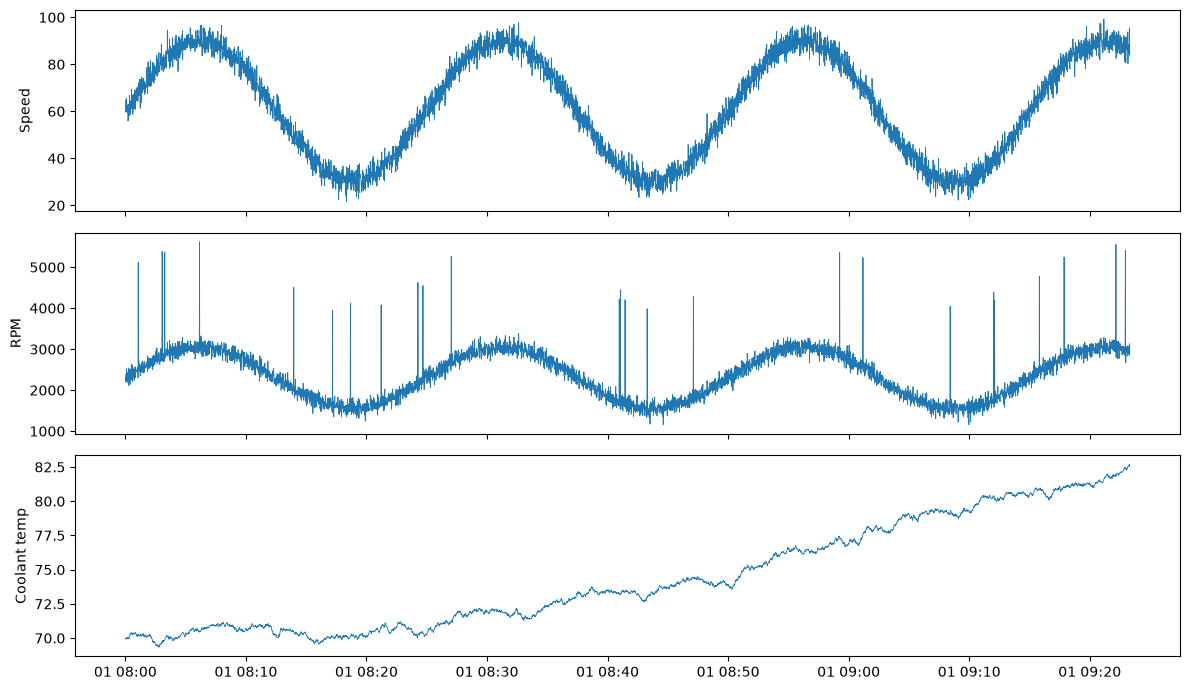

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
axes[0].plot(df["time"], df["speed"], linewidth=0.6)
axes[0].set_ylabel("Speed")
axes[1].plot(df["time"], df["rpm"], linewidth=0.6)
axes[1].set_ylabel("RPM")
axes[2].plot(df["time"], df["coolant_temp"], linewidth=0.6)
axes[2].set_ylabel("Coolant temp")
plt.tight_layout()
plt.savefig("../images/raw_signals.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
# For each second, compare RPM with the previous 60 seconds
df["rpm_roll_mean"] = df["rpm"].rolling(60).mean().shift(1)
df["rpm_roll_std"] = df["rpm"].rolling(60).std().shift(1)

# Z-score = how many "normal wiggles" away from the recent average
df["z"] = (df["rpm"] - df["rpm_roll_mean"]) / df["rpm_roll_std"]
df["anomaly"] = (df["z"].abs() > 4).astype(int)

print("Flagged as anomaly:", df["anomaly"].sum())

Flagged as anomaly: 27


In [17]:
caught = ((df["anomaly"] == 1) & (df["is_injected"] == 1)).sum()
missed = ((df["anomaly"] == 0) & (df["is_injected"] == 1)).sum()
false_alarms = ((df["anomaly"] == 1) & (df["is_injected"] == 0)).sum()

print("Injected spikes:", df["is_injected"].sum())
print("Caught:", caught)
print("Missed:", missed)
print("False alarms:", false_alarms)

Injected spikes: 25
Caught: 25
Missed: 0
False alarms: 2


In [9]:
fa = df[(df["anomaly"] == 1) & (df["is_injected"] == 0)]
spike_positions = df.index[df["is_injected"] == 1]

def within_60s_after_spike(i):
    return any(0 < i - s <= 60 for s in spike_positions)

near = sum(within_60s_after_spike(i) for i in fa.index)
print("False alarms:", len(fa))
print("Of these, within 60 seconds after a real spike:", near)
fa[["time", "rpm", "z"]].head(10)

False alarms: 30
Of these, within 60 seconds after a real spike: 0


,time,rpm,z
157,2026-01-01 08:02:37,3027.429464,3.353839
347,2026-01-01 08:05:47,2763.188136,-3.209686
575,2026-01-01 08:09:35,2479.425719,-3.789047
587,2026-01-01 08:09:47,2490.340451,-3.018013
668,2026-01-01 08:11:08,2215.331198,-3.288545
775,2026-01-01 08:12:55,1999.609217,-3.134473
933,2026-01-01 08:15:33,1429.726049,-3.691741
1729,2026-01-01 08:28:49,3194.641143,3.356666
1738,2026-01-01 08:28:58,3235.962629,3.347908
1758,2026-01-01 08:29:18,3247.776900,3.074889


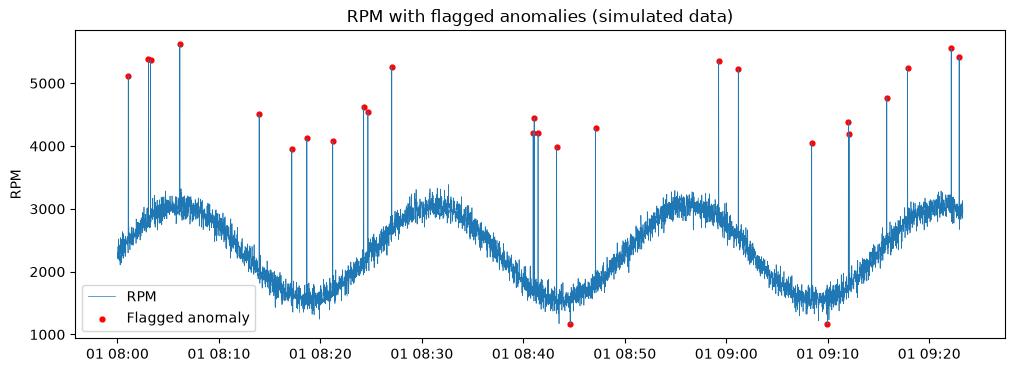

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))
plt.plot(df["time"], df["rpm"], linewidth=0.5, label="RPM")
flagged = df[df["anomaly"] == 1]
plt.scatter(flagged["time"], flagged["rpm"], color="red", s=12, label="Flagged anomaly")
plt.ylabel("RPM")
plt.title("RPM with flagged anomalies (simulated data)")
plt.legend()
plt.savefig("../images/rpm_anomalies.png", dpi=150, bbox_inches="tight")
plt.show()

In [19]:
import sqlite3

conn = sqlite3.connect("../data/vehicle.db")
df.to_sql("signals", conn, if_exists="replace", index=False)

q = """
SELECT strftime('%H:%M', time) AS minute,
       ROUND(AVG(speed), 1) AS avg_speed,
       ROUND(MAX(speed), 1) AS max_speed,
       ROUND(AVG(rpm), 0)   AS avg_rpm,
       ROUND(MAX(rpm), 0)   AS max_rpm,
       SUM(anomaly)         AS anomalies
FROM signals
GROUP BY minute
ORDER BY minute;
"""
pd.read_sql(q, conn).head(10)

,minute,avg_speed,max_speed,avg_rpm,max_rpm,anomalies
0,08:00,63.2,70.3,2385.0,2636.0,0
1,08:01,70.9,81.1,2618.0,5119.0,1
2,08:02,77.8,88.6,2741.0,3027.0,0
3,08:03,83.2,94.6,2972.0,5386.0,2
4,08:04,87.0,94.2,2979.0,3286.0,0
5,08:05,89.5,95.6,3019.0,3206.0,0
6,08:06,90.3,96.6,3080.0,5619.0,1
7,08:07,88.5,96.5,3009.0,3195.0,0
8,08:08,84.5,91.8,2909.0,3156.0,0
9,08:09,80.5,87.6,2819.0,3076.0,0


In [12]:
for th in [3, 4, 5, 6]:
    flag = (df["z"].abs() > th)
    caught = (flag & (df["is_injected"] == 1)).sum()
    false_alarms = (flag & (df["is_injected"] == 0)).sum()
    print("Threshold", th, "| caught:", caught, "| false alarms:", false_alarms)

Threshold 3 | caught: 25 | false alarms: 30
Threshold 4 | caught: 25 | false alarms: 2
Threshold 5 | caught: 24 | false alarms: 0
Threshold 6 | caught: 24 | false alarms: 0


In [13]:
missed5 = df[(df["z"].abs() <= 5) & (df["is_injected"] == 1)]
missed5[["time", "rpm", "z"]]

,time,rpm,z
2487,2026-01-01 08:41:27,4205.334371,4.930344
